# ARTI 404 – Image Processing 2240002411
## Lab 4: Intensity Transformations and Filtering – Spatial Domain

## Setup

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
from skimage import data, img_as_float, exposure, io

os.makedirs('images', exist_ok=True)

def show_with_hist(image, title, value_range=(0, 255), fname=None):
    """Display a grayscale image above its histogram."""
    fig = plt.figure(figsize=(10, 7))
    fig.add_subplot(2, 1, 1)
    plt.imshow(image, cmap='gray')
    plt.axis('off')
    plt.title(title)
    fig.add_subplot(2, 1, 2)
    plt.hist(image.flat, bins=256, range=value_range)
    plt.xlabel('gray level values')
    plt.ylabel('Number of pixels')
    plt.tight_layout()
    if fname:
        plt.savefig(os.path.join('images', fname), dpi=100)
    plt.show()

# Part A – Lab procedure
### Task 1: Thresholding with fixed thresholds
The manual's Parrot image isn't included in skimage, so the moon image is used. Matplotlib replaces `cv2.imshow` so the results render inside the notebook.

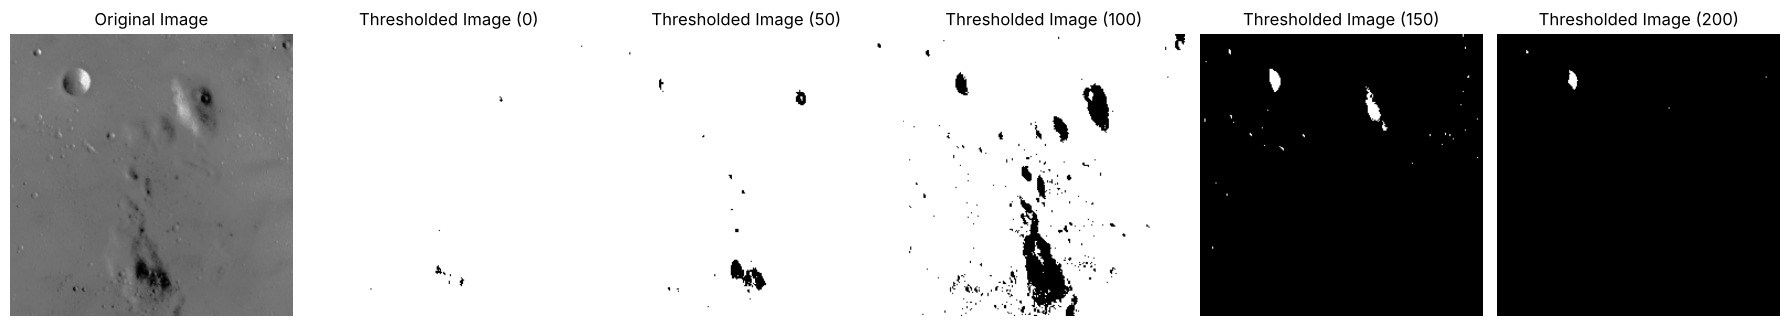

In [2]:
import cv2

img = data.moon()   # grayscale uint8
threshold_values = [0, 50, 100, 150, 200]

fig, axes = plt.subplots(1, len(threshold_values) + 1, figsize=(18, 4))
axes[0].imshow(img, cmap='gray'); axes[0].set_title('Original Image')
for ax, t in zip(axes[1:], threshold_values):
    ret, thresh = cv2.threshold(img, t, 255, cv2.THRESH_BINARY)
    ax.imshow(thresh, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Thresholded Image ({t})')
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.savefig('images/thresholding.png', dpi=100)
plt.show()

### Task 2: Histogram processing – moon image and 2nd–98th percentile contrast stretch

2nd percentile = 78.0, 98th percentile = 129.0


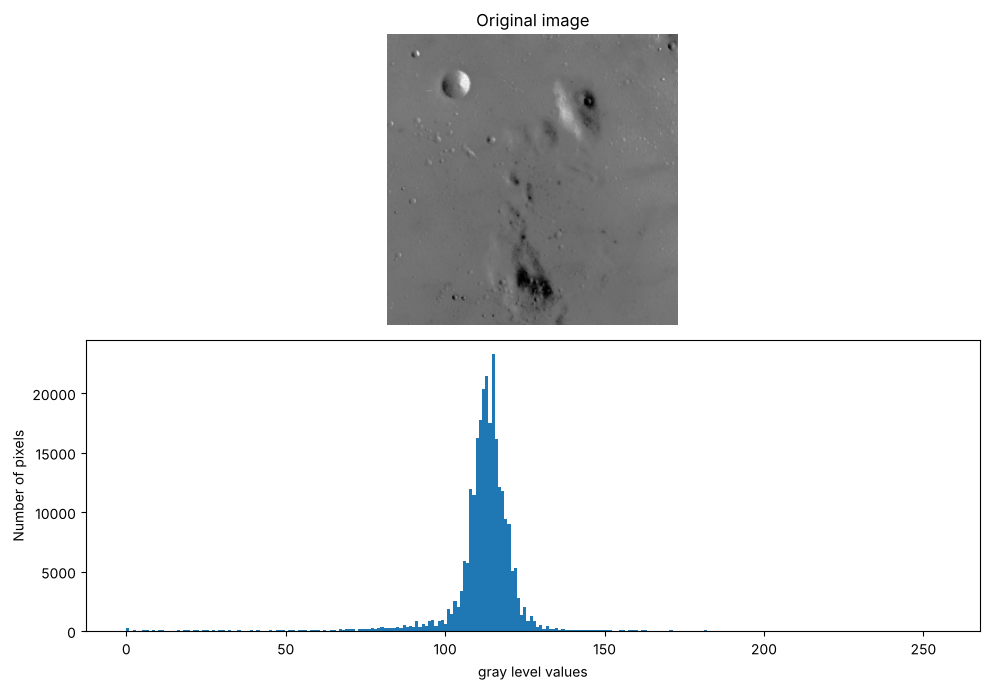

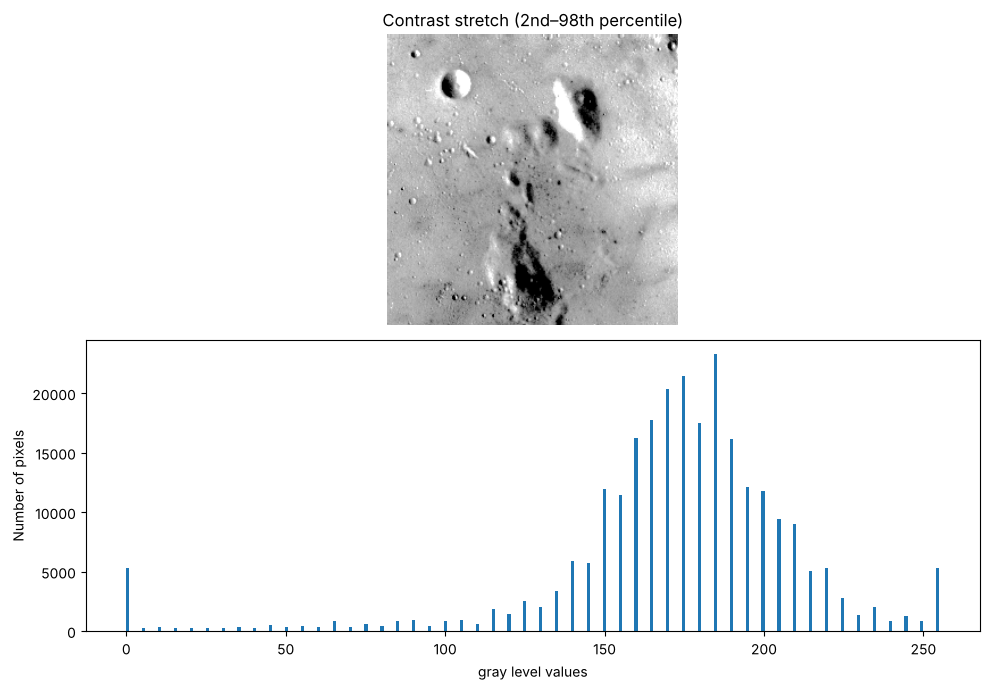

In [3]:
img = data.moon()
io.imsave('images/moon_original.png', img)

p2, p98 = np.percentile(img, (2, 98))
img_rescale = exposure.rescale_intensity(img, in_range=(p2, p98))
print(f'2nd percentile = {p2}, 98th percentile = {p98}')

show_with_hist(img, 'Original image', fname='moon_original_hist.png')
show_with_hist(img_rescale, 'Contrast stretch (2nd–98th percentile)', fname='moon_stretch_2_98_hist.png')

# Part B – Assessment
## Assessment Task 1

3rd percentile = 87.0, 80th percentile = 118.0


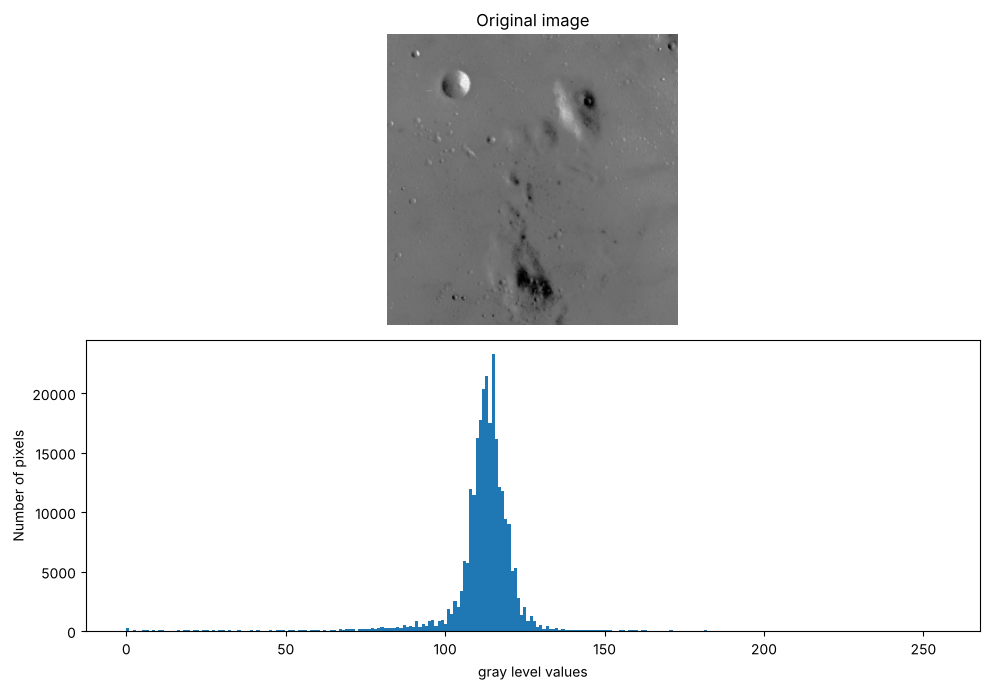

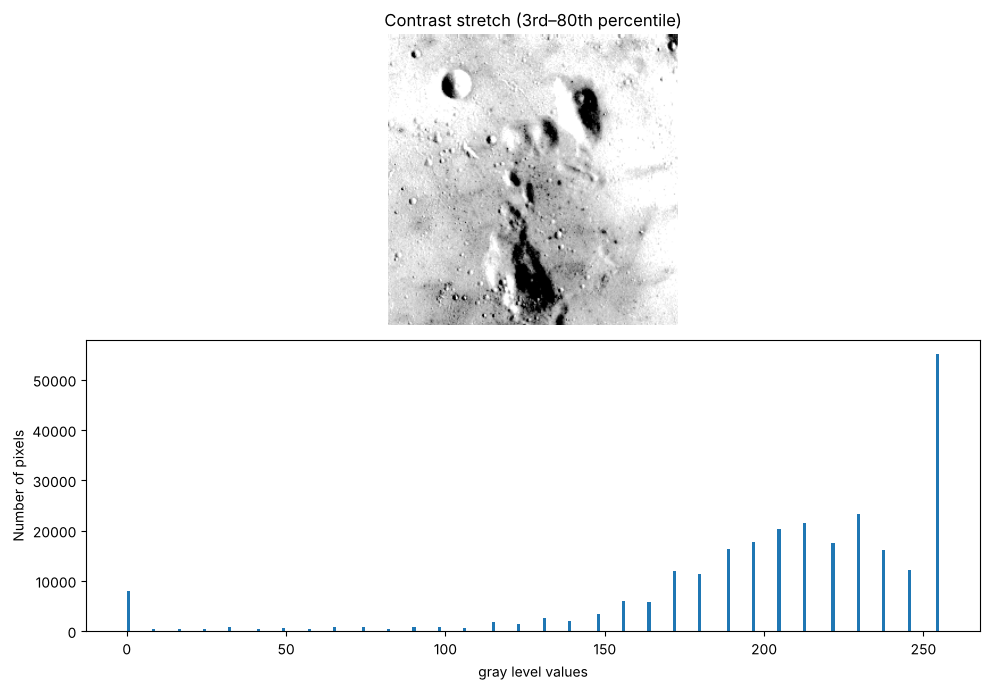

In [4]:
p3, p80 = np.percentile(img, (3, 80))
print(f'3rd percentile = {p3}, 80th percentile = {p80}')

img_rescale_3_80 = exposure.rescale_intensity(img, in_range=(p3, p80))
io.imsave('images/moon_stretch_3_80.png', img_rescale_3_80)

show_with_hist(img, 'Original image', fname=None)
show_with_hist(img_rescale_3_80, 'Contrast stretch (3rd–80th percentile)', fname='moon_stretch_3_80_hist.png')

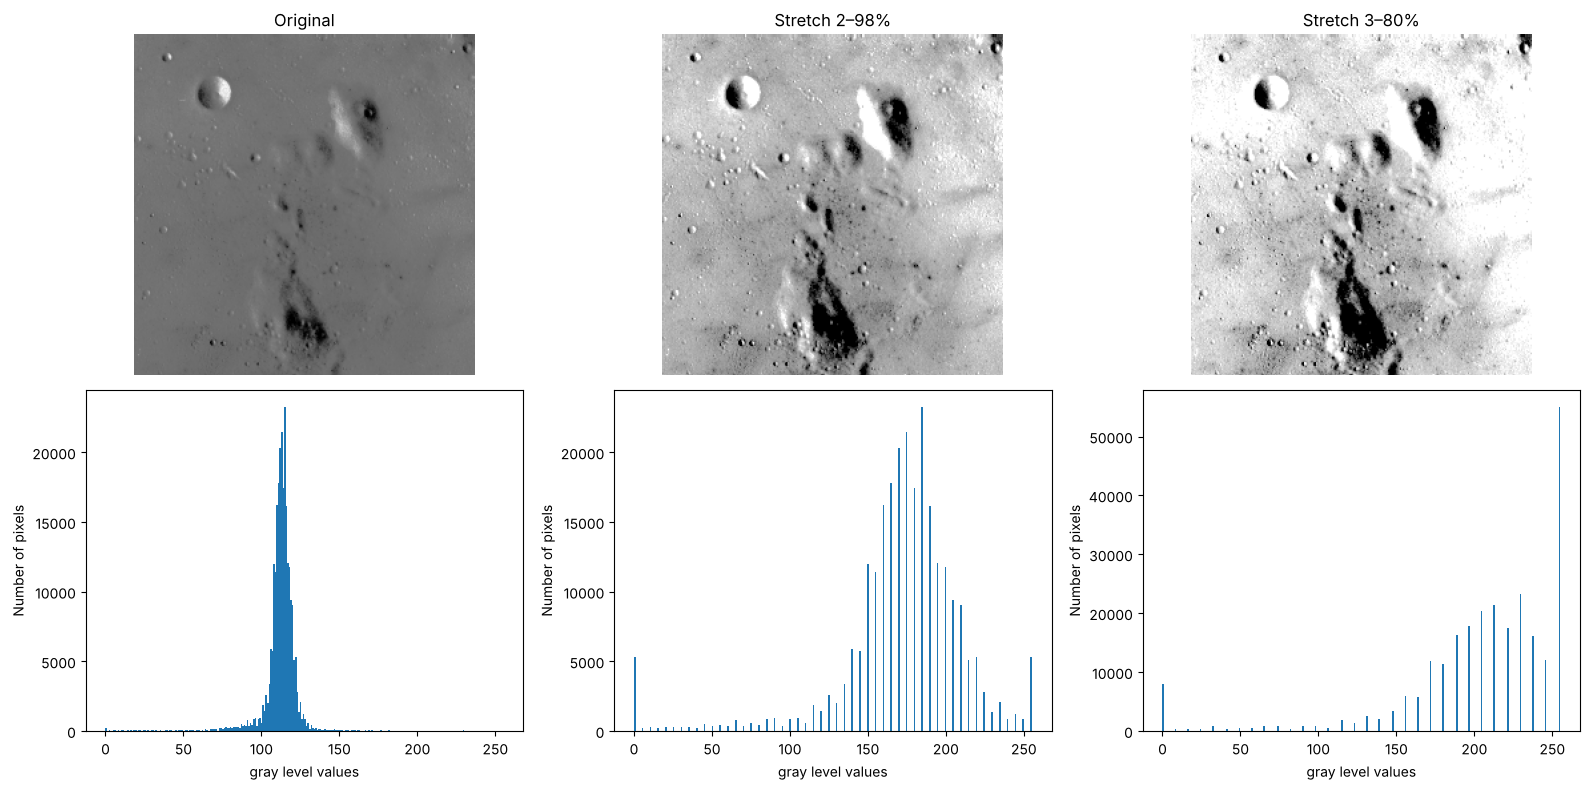

Pixels saturated at 255 — 2–98%: 2.0 % | 3–80%: 21.0 %


In [5]:
# Side-by-side comparison of the two stretches
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for col, (im, t) in enumerate([(img, 'Original'),
                               (img_rescale, 'Stretch 2–98%'),
                               (img_rescale_3_80, 'Stretch 3–80%')]):
    axes[0, col].imshow(im, cmap='gray'); axes[0, col].set_title(t); axes[0, col].axis('off')
    axes[1, col].hist(im.flat, bins=256, range=(0, 255))
    axes[1, col].set_xlabel('gray level values'); axes[1, col].set_ylabel('Number of pixels')
plt.tight_layout(); plt.savefig('images/stretch_comparison.png', dpi=100); plt.show()

print('Pixels saturated at 255 — 2–98%:', round((img_rescale == 255).mean() * 100, 1), '%',
      '| 3–80%:', round((img_rescale_3_80 == 255).mean() * 100, 1), '%')

## Assessment Task 2


dtype: float64 | min: 0.00091552734375 | max: 1.0


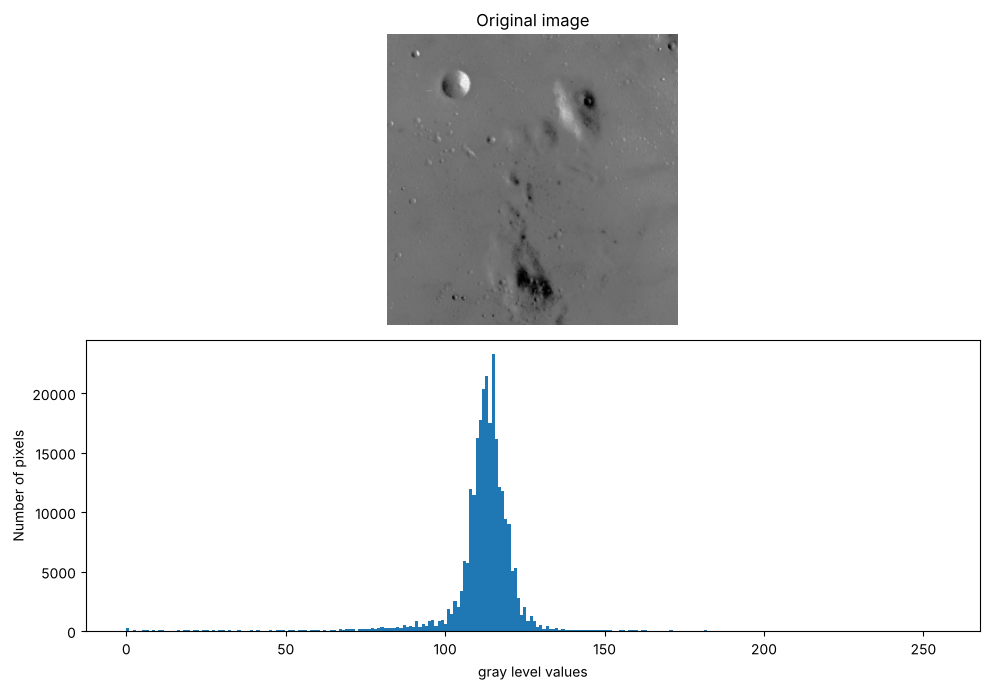

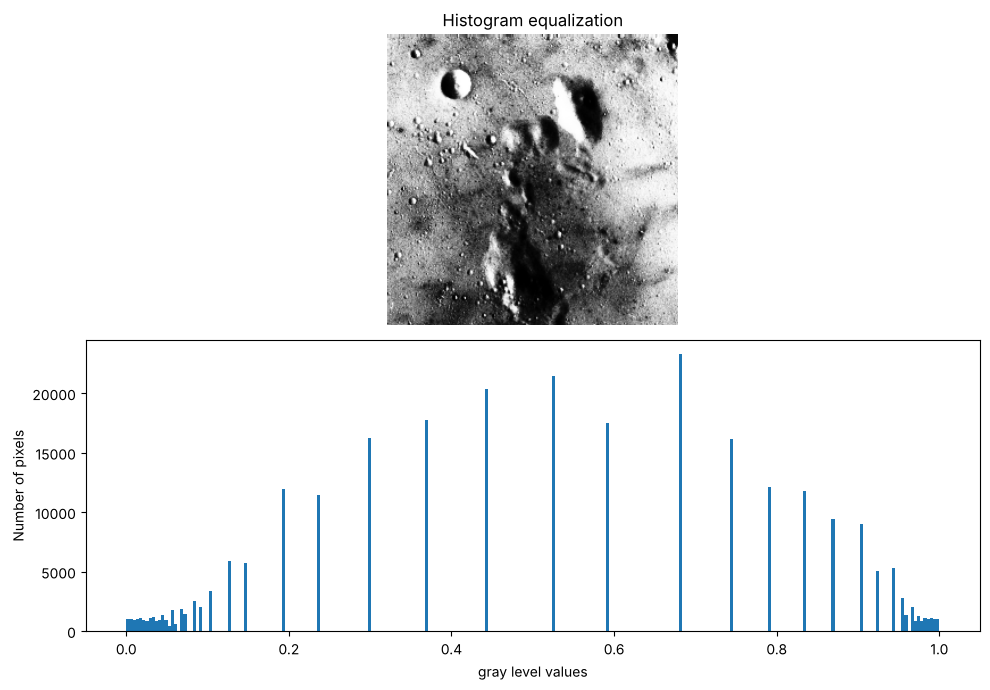

In [6]:
img_eq = exposure.equalize_hist(img)
print('dtype:', img_eq.dtype, '| min:', img_eq.min(), '| max:', img_eq.max())
io.imsave('images/moon_equalized.png', (img_eq * 255).astype(np.uint8))

show_with_hist(img, 'Original image')
show_with_hist(img_eq, 'Histogram equalization', value_range=(0, 1), fname='moon_equalized_hist.png')

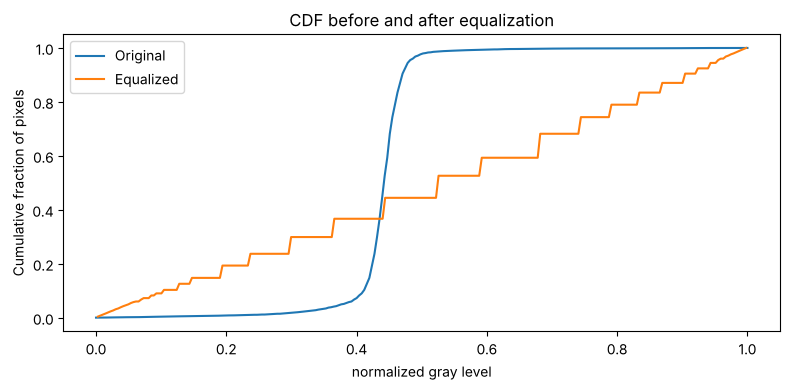

In [7]:
# Cumulative distribution before and after equalization
cdf_o, bins_o = exposure.cumulative_distribution(img)
cdf_e, bins_e = exposure.cumulative_distribution(img_eq)
plt.figure(figsize=(8, 4))
plt.plot(bins_o / 255, cdf_o, label='Original')
plt.plot(bins_e, cdf_e, label='Equalized')
plt.xlabel('normalized gray level'); plt.ylabel('Cumulative fraction of pixels')
plt.title('CDF before and after equalization'); plt.legend()
plt.tight_layout(); plt.savefig('images/moon_cdf.png', dpi=100); plt.show()

## Assessment Task 3

Chelsea: (300, 451, 3) | Rocket: (427, 640, 3)


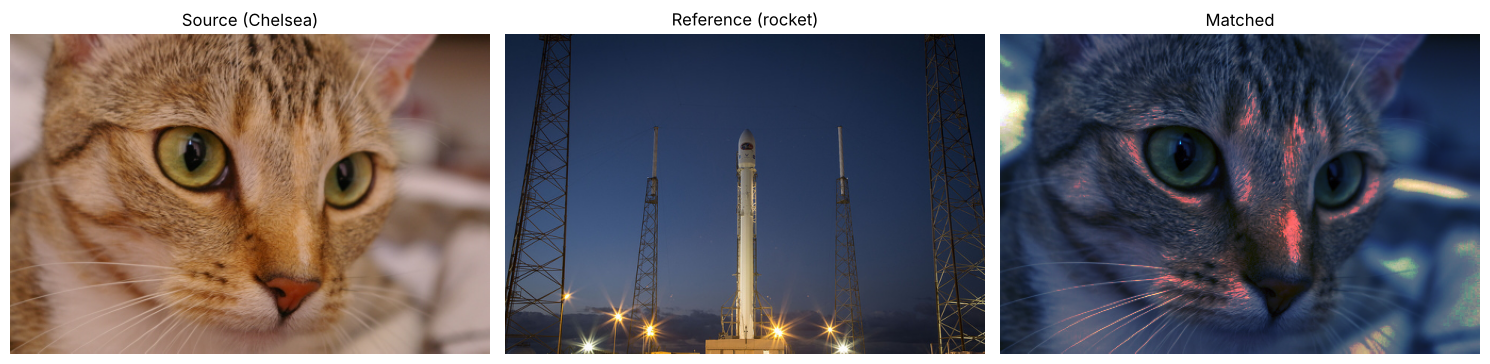

In [8]:
from skimage.exposure import match_histograms

reference = data.rocket()
image = data.chelsea()
print('Chelsea:', image.shape, '| Rocket:', reference.shape)

matched = match_histograms(image, reference, channel_axis=-1)
io.imsave('images/chelsea_source.png', image)
io.imsave('images/rocket_reference.png', reference)
io.imsave('images/chelsea_matched.png', np.clip(matched, 0, 255).astype(np.uint8))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, im, t in zip(axes, [image, reference, matched], ['Source (Chelsea)', 'Reference (rocket)', 'Matched']):
    ax.imshow(np.clip(im, 0, 255).astype(np.uint8)); ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.savefig('images/histogram_matching.png', dpi=100); plt.show()

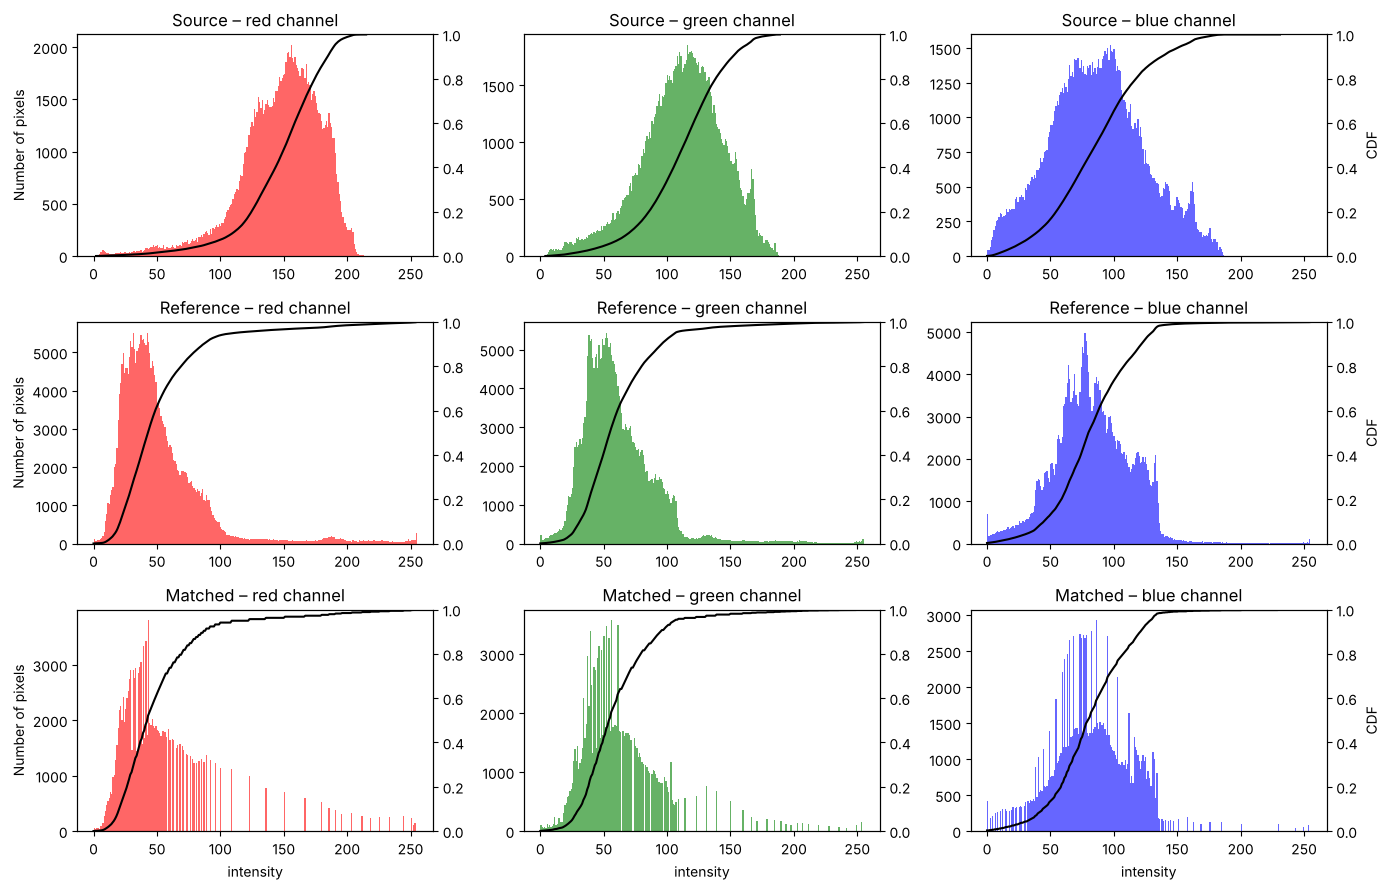

In [9]:
# Per-channel histograms and CDFs for source, reference and matched images
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
colors = ['red', 'green', 'blue']
for row, (im, t) in enumerate([(image, 'Source'), (reference, 'Reference'), (matched, 'Matched')]):
    for c, col in enumerate(colors):
        ch = np.clip(im[..., c], 0, 255).astype(np.uint8)
        ax = axes[row, c]
        ax.hist(ch.ravel(), bins=256, range=(0, 255), color=col, alpha=0.6)
        ax2 = ax.twinx()
        cdf, bins = exposure.cumulative_distribution(ch)
        ax2.plot(bins, cdf, 'k'); ax2.set_ylim(0, 1)
        ax.set_title(f'{t} – {col} channel')
        if c == 0: ax.set_ylabel('Number of pixels')
        if c == 2: ax2.set_ylabel('CDF')
        if row == 2: ax.set_xlabel('intensity')
plt.tight_layout(); plt.savefig('images/histogram_matching_hist.png', dpi=100); plt.show()